Saving Heart_Disease.csv to Heart_Disease (1).csv
Shape of dataset: (50000, 10)

Column names:
Index(['Age', 'Weight', 'Height', 'BMI', 'Smoking', 'Alcohol_Intake',
       'Physical_Activity', 'Diet', 'Stress_Level', 'Hypertension'],
      dtype='object')

Missing values:
Age                      0
Weight                   0
Height                   0
BMI                      0
Smoking                  0
Alcohol_Intake       20109
Physical_Activity        0
Diet                     0
Stress_Level             0
Hypertension             0
dtype: int64
Input shape: (50000, 9)
Target shape: (50000,)
   Age  Weight  Height   BMI  Smoking  Alcohol_Intake  Physical_Activity  \
0   48      78     157  26.4        2               3                  2   
1   35      73     163  33.0        2               1                  0   
2   79      88     152  32.3        2               3                  1   
3   75     106     171  37.4        2               2                  1   
4   34      65   

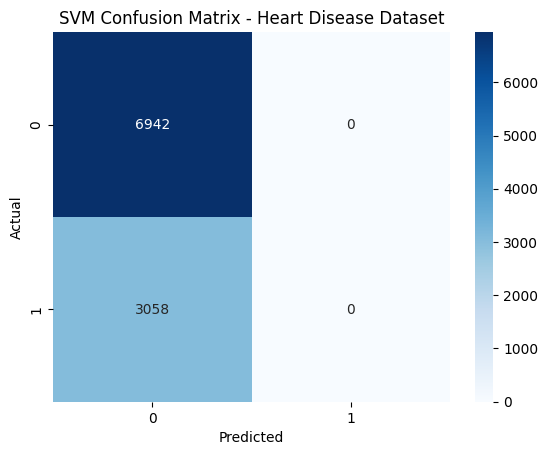

              precision    recall  f1-score   support

           0       0.69      1.00      0.82      6942
           1       0.00      0.00      0.00      3058

    accuracy                           0.69     10000
   macro avg       0.35      0.50      0.41     10000
weighted avg       0.48      0.69      0.57     10000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Import required libraries

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Upload the CSV file
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("Heart_Disease.csv")
df.head()

# Display information about the dataset
print("Shape of dataset:", df.shape)
print("\nColumn names:")
print(df.columns)
print("\nMissing values:")
print(df.isnull().sum())

# Handle missing values by imputing with mode for 'Alcohol_Intake'
mode_alcohol_intake = df['Alcohol_Intake'].mode()[0]
df['Alcohol_Intake'].fillna(mode_alcohol_intake, inplace=True)
print("\nMissing values after imputation:")
print(df.isnull().sum())

# Separate features and target
X = df.drop("Hypertension", axis=1)
y = df["Hypertension"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

# Encode categorical input features
encoder = LabelEncoder()

for column in X.columns:
    # Check if the column is of object type (string) before encoding
    if X[column].dtype == 'object':
        X[column] = encoder.fit_transform(X[column])

# Encode target variable
if y.dtype == 'object':
    y = encoder.fit_transform(y)

print(X.head())
print(y[:10])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Standardize the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create SVM model using RBF kernel
model = SVC(kernel="rbf")

# Train the model
model.fit(X_train, y_train)

# Make predictions on test data
y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred[:20])

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy in percentage:", accuracy * 100, "%")

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix - Heart Disease Dataset")
plt.show()

# Display classification report
print(classification_report(y_test, y_pred))